In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

df.info()

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


# **Data Cleaning**

In [5]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# **Check Missing Values**

In [6]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


# **Remove Missing Rows**

In [7]:
df = df.dropna()

# **Check Duplicate**

In [8]:
df.duplicated().sum()

np.int64(0)

# **Exploratory Data Analysis**

In [10]:
df["Churn"].value_counts() #overall_churn

,count
Churn,
No,5163
Yes,1869


In [12]:
churn_rate = (

df["Churn"]
.value_counts(normalize=True)
*100

)

print(churn_rate) #churn_percentage

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


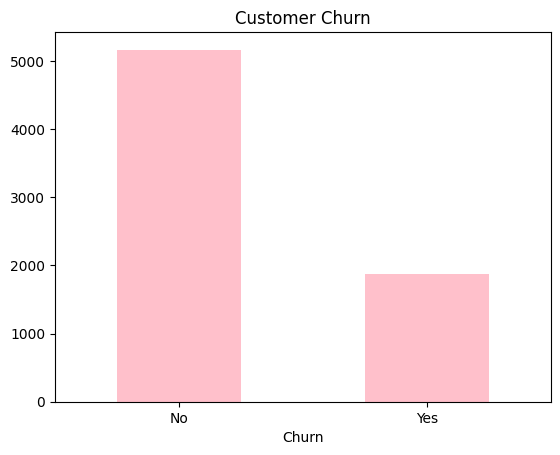

In [15]:
df["Churn"].value_counts().plot(
    kind="bar",
    color="pink"
)

plt.title("Customer Churn")
plt.xticks(rotation=0)

plt.show()

# **Churn by Contract Type**

In [16]:
pd.crosstab(
df["Contract"],
df["Churn"]
)

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


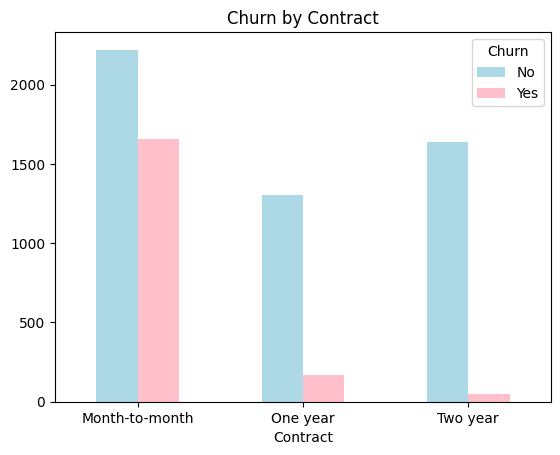

In [22]:
pd.crosstab(
    df["Contract"],
    df["Churn"]
).plot(
    kind="bar",
    color=["lightblue", "pink"]
)

plt.title("Churn by Contract")
plt.xticks(rotation=0)

plt.show()

**Insight**

Month-to-month customers churn the most.


# **Churn by Senior Citizen**

In [23]:
pd.crosstab(

df["SeniorCitizen"],
df["Churn"]

)

Churn,No,Yes
SeniorCitizen,,
0,4497,1393
1,666,476


(array([0, 1]), [Text(0, 0, '0'), Text(1, 0, '1')])

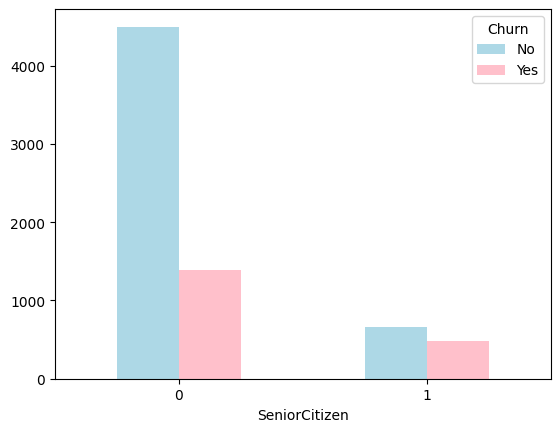

In [27]:
pd.crosstab(

df["SeniorCitizen"],
df["Churn"]

).plot(
    kind="bar",
    color=["lightblue", "pink"] )

plt.xticks(rotation=0)

**Insight**

Senior citizens are more likely to churn.


# **Monthly Charges vs Churn**

In [28]:
yes = df[df["Churn"]=="Yes"]

no = df[df["Churn"]=="No"]

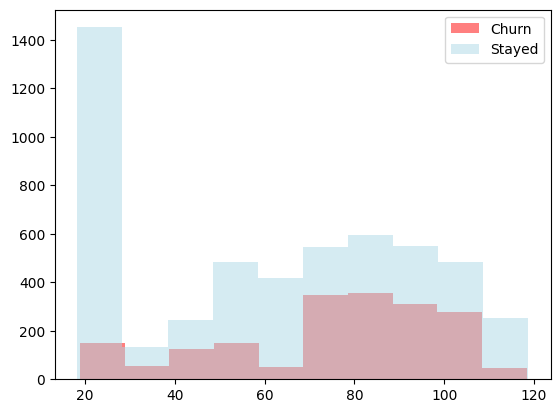

In [36]:
plt.hist(
    yes["MonthlyCharges"],
    alpha=0.5,
    color="red"
)

plt.hist(
    no["MonthlyCharges"],
    alpha=0.5,
    color="lightblue"
)

plt.legend(["Churn", "Stayed"])

plt.show()

**Insight**

Customers with higher monthly charges tend to churn more.


# **Tenure vs Churn**

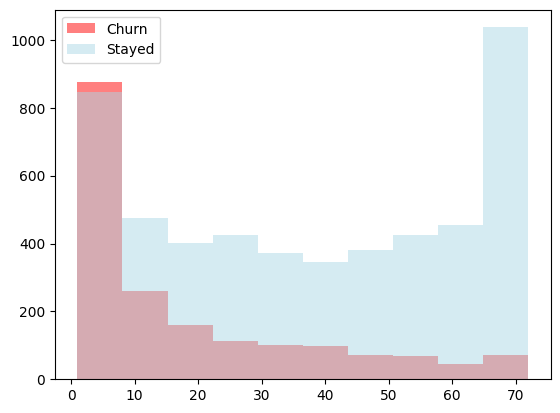

In [35]:
plt.hist(

yes["tenure"],
alpha=0.5,
color="red"
)

plt.hist(

no["tenure"],
alpha=0.5,
color="lightblue"
)

plt.legend(["Churn","Stayed"])

plt.show()

**Insight**

Customers leaving usually have shorter tenure.


# **Payment Method Analysis**

In [37]:
pd.crosstab(

df["PaymentMethod"],
df["Churn"]

)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1284,258
Credit card (automatic),1289,232
Electronic check,1294,1071
Mailed check,1296,308


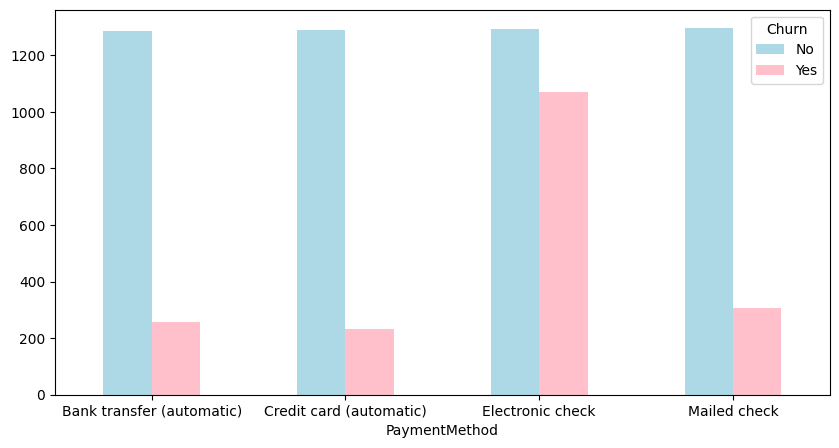

In [41]:
pd.crosstab(

df["PaymentMethod"],
df["Churn"]

).plot(
kind="bar",
figsize=(10,5),
color=["lightblue", "pink"]
)

plt.xticks(rotation=0)
plt.show()

### **Insight**
Electronic check users have the highest churn.


# **Business Recommendations**

**Recommendation 1**

Encourage month-to-month customers to switch to yearly contracts by offering discounts.


**Recommendation 2**

Focus on customers in their first year by:



*  Loyalty rewards

*   Welcome promotions

*   Early customer support






**Recommendation 3**

Promote value-added services:


*   Online Security

*   Tech Support
*   Device Protection

These services can improve customer retention.



**Recommendation 4**

Investigate why electronic check customers churn more frequently and improve their payment experience.


# **Conclusion**

Using Python, this project explored customer churn patterns through data cleaning, exploratory data analysis (EDA), and visualization techniques. The analysis revealed that customers with month-to-month contracts, shorter tenure, higher monthly charges, and electronic check payment methods are more likely to churn. Python made it possible to efficiently preprocess the data, uncover meaningful trends, and transform raw customer information into actionable business insights. These findings can help companies develop targeted retention strategies and improve long-term customer loyalty.